### ASTR 8070: Astrostatistics
***N. Pol***
___

# Homework 4
### Due: Wednesday, Oct. 14 11.59pm CST
---

## Problem 1

This problem uses a dataset in `/coursework/homeworks/hw_data/`.

1) Read in `hw4_data_1.npy`. This is a (10 x 2) numpy array, with voltage measurements in the first column and heteroscedastic voltage uncertainties in the second column. Compute the sample mean and the standard error on the sample mean for this data.

2) Fit the appropriate ln-likelihood function and find the best-fit mean voltage.

3) Compute and plot the Bayesian posterior probability density (*not the log posterior*) for the mean voltage assuming a uniform prior for the mean in the range 3 to 7. Make sure this posterior pdf is normalized!

4) By either drawing samples from this posterior, or using your gridded posterior pdf to make a cdf, find the equal-tailed 68.3% credible region for the mean, and compare the upper and lower boundaries to the sample mean plus/minus the standard error, respectively. *Also* find the MAP value of the mean.

5) Repeat (3) and (4) this time with a prior on the mean that is uniform in the range 4.6 to 5.4. 

6) Now, imagine that we read an old paper about the experiment that gave us the voltage measurements, and they found that the mean was actually $6\pm0.3$. Repeat (3) and (4) this time with a Gaussian prior on the mean centered at $6$ with standard deviation of $0.3$.

7) Plot all of the normalized posterior pdfs for $\mu$ from (3), (5), and (6) on the same plot, making sure that the xlim of the plot spans 0 to 10.

8) You have made sure that the posterior pdfs are properly normalized, but until now you have ignored the meaning of that normalization constant. It is the Bayesian evidence for the particular model you have applied! Compute the evidence under a new model where the prior for the mean is a delta function at the best-fit value you found in (1) *(think about this and don't just immediately go looking for a `scipy.stats` delta function)*. Compare this to the evidence found under the prior in (3). Taking ratios to make a Bayes factor, which model is favored? Is there much of an Occam penalty by having the wide prior compared to knowing the mean exactly? 

### Solution

In [1]:
#part 1
#imports
import numpy as np
from scipy import stats

#load data
data1 = np.load("hw_data/hw4_data_1.npy")

#separate two columns
voltages = data1[:, 0]
uncertainties = data1[:, 1]

#calculate mean and standard error
mean = np.mean(voltages)
error = stats.sem(voltages)
print("mean:", mean)
print("error:", error)

mean: 5.106
error: 0.32838053806183115


In [2]:
#part 2
#function to get ln-likelihood
def ln_likelihood(mu):
    return -0.5 * np.sum((voltages - mu)**2 / uncertainties**2 + np.log(2*np.pi*uncertainties**2))

#function to find best-fit
def neg_ln_likelihood(mu):
    return -ln_likelihood(mu)

from scipy.optimize import minimize
bfmv = minimize(neg_ln_likelihood, x0=[np.mean(voltages)])
print("best-fit mean voltage:", bfmv.x[0])

best-fit mean voltage: 4.942118214542556


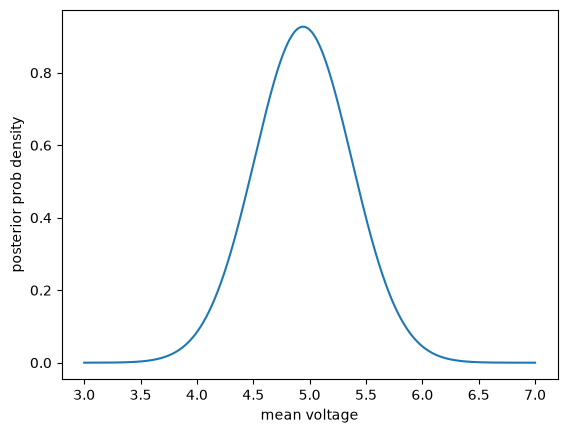

In [3]:
#part 3
import matplotlib.pyplot as plt

#getting posterior
mu_grid = np.linspace(3, 7, 2000)
prior = np.ones_like(mu_grid) / (7-3)
lnL = np.array([ln_likelihood(mu) for mu in mu_grid])
likelihood = np.exp(lnL - lnL.max())
posterior = likelihood * prior
posterior /= np.trapezoid(posterior, mu_grid)

#plot
plt.plot(mu_grid, posterior)
plt.xlabel("mean voltage")
plt.ylabel("posterior prob density")
plt.show()

In [4]:
#part 4
from scipy.integrate import cumulative_trapezoid

#getting cdf
cdf = cumulative_trapezoid(posterior, mu_grid, initial=0)
tail = (1-0.683) / 2

#boundaries
mu_low = np.interp(tail, cdf, mu_grid)
mu_high = np.interp(1-tail, cdf, mu_grid)

#MAP
map_value = mu_grid[np.argmax(posterior)]
print("credible region:", mu_low, mu_high)
print("sample mean +/- error:", mean-error, mean+error)
print("MAP:", map_value)

credible region: 4.511601332631391 5.372639009133218
sample mean +/- error: 4.777619461938169 5.434380538061831
MAP: 4.942971485742872


In [11]:
#credible region is close to upper and lower boundaries

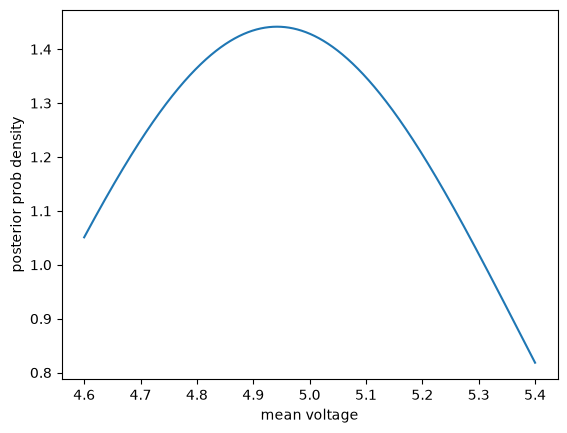

credible region: 4.735092008667222 5.23837100172111
sample mean +/- error: 4.777619461938169 5.434380538061831
MAP: 4.942171085542771


In [12]:
#part 5
#repeating previous steps with new prior
mu_grid2 = np.linspace(4.6, 5.4, 2000)
prior2 = np.ones_like(mu_grid2) / (5.4-4.6)
lnL2 = np.array([ln_likelihood(mu) for mu in mu_grid2])
likelihood2 = np.exp(lnL2 - lnL2.max())
posterior2 = likelihood2 * prior2
posterior2 /= np.trapezoid(posterior2, mu_grid2)

#plot
plt.plot(mu_grid2, posterior2)
plt.xlabel("mean voltage")
plt.ylabel("posterior prob density")
plt.show()

cdf2 = cumulative_trapezoid(posterior2, mu_grid2, initial=0)
tail = (1-0.683) / 2
mu_low2 = np.interp(tail, cdf2, mu_grid2)
mu_high2 = np.interp(1-tail, cdf2, mu_grid2)
map_value2 = mu_grid2[np.argmax(posterior2)]
print("credible region:", mu_low2, mu_high2)
print("sample mean +/- error:", mean-error, mean+error)
print("MAP:", map_value2)

In [13]:
#credible region is close to upper and lower boundaries

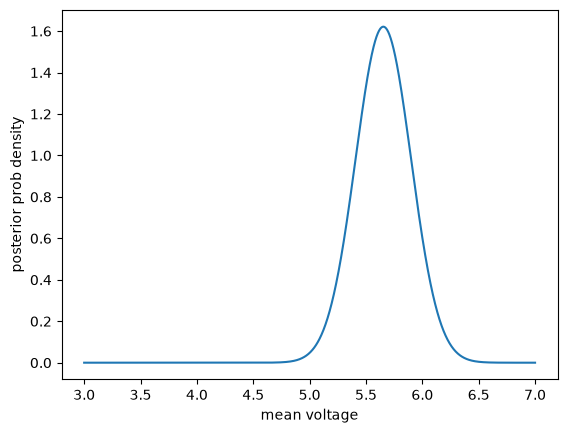

credible region: 5.407677318983893 5.900166537921953
sample mean +/- error: 4.777619461938169 5.434380538061831
MAP: 5.653326663331665


In [17]:
#part 6
#repeating previous steps with new Gaussian prior
mu_grid3 = np.linspace(3, 7, 2000)
prior3 = stats.norm(loc=6, scale=0.3).pdf(mu_grid3)
lnL3 = np.array([ln_likelihood(mu) for mu in mu_grid3])
likelihood3 = np.exp(lnL3 - lnL3.max())
posterior3 = likelihood3 * prior3
posterior3 /= np.trapezoid(posterior3, mu_grid3)

# plot
plt.plot(mu_grid3, posterior3)
plt.xlabel("mean voltage")
plt.ylabel("posterior prob density")
plt.show()


cdf3 = cumulative_trapezoid(posterior3, mu_grid3, initial=0)
cdf3 /= cdf3[-1]
tail = (1 - 0.683) / 2
mu_low3 = np.interp(tail, cdf3, mu_grid3)
mu_high3 = np.interp(1 - tail, cdf3, mu_grid3)
map_value3 = mu_grid3[np.argmax(posterior3)]

print("credible region:", mu_low3, mu_high3)
print("sample mean +/- error:", mean - error, mean + error)
print("MAP:", map_value3)

In [18]:
#credible region is higher than upper and lower boundaries

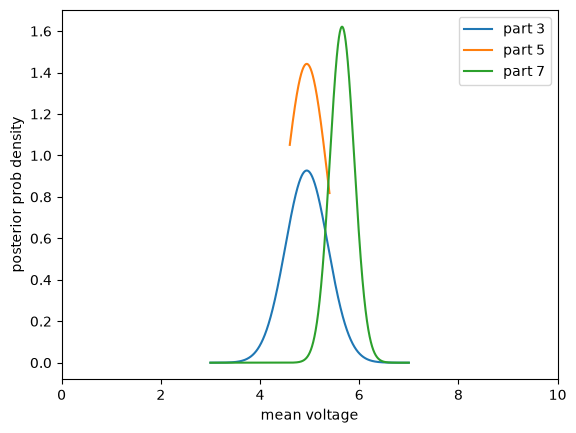

In [19]:
#part 7
plt.plot(mu_grid, posterior, label='part 3')
plt.plot(mu_grid2, posterior2, label='part 5')
plt.plot(mu_grid3, posterior3, label='part 7')
plt.xlim(0, 10)
plt.xlabel("mean voltage")
plt.ylabel("posterior prob density")
plt.legend()
plt.show()

In [20]:
#part 8
#calculating evidence and bayes factor
lnZ_delta = ln_likelihood(mean)
lnL_grid = np.array([ln_likelihood(m) for m in mu_grid])
lnL_max = lnL_grid.max()
lnZ_uniform = lnL_max + np.log(np.trapezoid(np.exp(lnL_grid - lnL_max) * prior, mu_grid))
ln_B = lnZ_delta - lnZ_uniform
Z_delta = np.exp(lnZ_delta)
Z_uniform = np.exp(lnZ_uniform)
bayes = Z_delta / Z_uniform
print("evidence Z (delta):", Z_delta)
print("evidence Z (uniform):", Z_uniform)
print("Bayes factor:", bayes)

evidence Z (delta): 9.975417031611396e-08
evidence Z (uniform): 2.8918714351047346e-08
Bayes factor: 3.449467673603587


In [28]:
#delta model is favored
#not much occam penalty

## Problem 2

This problem uses a dataset in `/coursework/homeworks/hw_data/`.

1) Read in `hw4_data_2.npy`, which is a (3 x 20) numpy array that you used in `Lecture_9`. Set `x, y, sigma_y = data`. 

We're going to do some polynomial fits to this data just like in `Lecture 9`. However, in all cases you should **keep the $y$-intercept fixed at $-0.23$**. 

2) Use the following code to compute the un-normalized posterior pdf (i.e. just the likelihood x prior) on a grid of the linear coefficient (i.e. the slope) of a linear model, with a uniform prior between 0.5 and 1.5. Plot this posterior pdf. Remember this is just a one-dimensional model because the $y$-intercept is fixed. I advise a grid size of 100.

In [21]:
#Functions to do a polynomial fit, and compute the likelihood
def polynomial_fit(theta, x):
    """Polynomial model of degree (len(theta) - 1)"""
    # For a polynomial with order 1, this gives theta_0 + theta_1*x
    # For a polynomial with order 2, this gives theta_0 + theta_1*x + theta_2*x^2, etc.
    return sum(t * x ** n for (n, t) in enumerate(theta))

# compute the data log-likelihood given a model
def logL(theta, data, model=polynomial_fit):
    """Gaussian log-likelihood of the model at theta"""
    x, y, sigma_y = data
    y_fit = model(theta, x)
    return sum(stats.norm.logpdf(*args) 
               for args in zip(y, y_fit, sigma_y))

3) Using your 1D gridded likelihood-x-prior, compute the Bayesian evidence of this linear model. This may be a big number!

4) Now compute the joint 2D posterior pdf (again just the likelihood x prior) of linear and quadratic coefficients of a quadratic model. Give the linear coefficient a uniform prior between 0.5 and 1.5. Give the quadratic coefficient a uniform prior between -1 and 0.25. Plot this two-dimensional posterior. Remember this is a two-dimensional model because the $y$-intercept is fixed. I advise a grid size of 100 in each model dimension.

5) Using your 2D gridded likelihood-x-prior, compute the Bayesian evidence of the quadratic model. 

6) Calculate the Bayes factor for a linear versus quadratic model. How does this compare/contrast with the BIC model comparison in the lecture? 

### Solution

In [22]:
#part 1
#load data
data2 = np.load("hw_data/hw4_data_2.npy")
x, y, sigma_y = data2

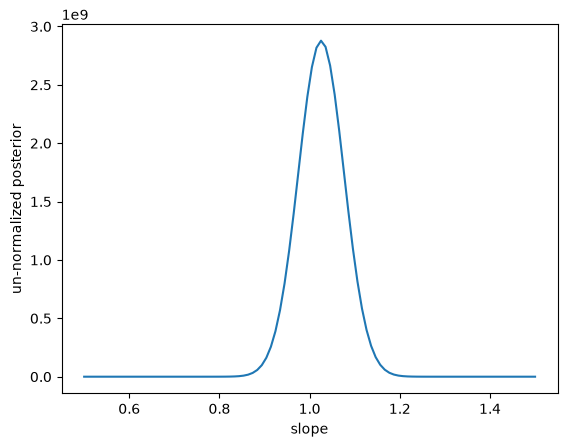

In [23]:
#part 2
#calculating posterior
intercept = -0.23
slope_grid = np.linspace(0.5, 1.5, 100)
prior4 = np.ones_like(slope_grid) / (1.5-0.5)
lnL_grid = np.array([logL([intercept, m], data2) for m in slope_grid])
likelihood4 = np.exp(lnL_grid)
posterior4 = likelihood4 * prior4

#plot
plt.plot(slope_grid, posterior4)
plt.xlabel("slope")
plt.ylabel("un-normalized posterior")
plt.show()

In [25]:
#part 3
#calculating evidence of linear model
prior_slope = np.ones_like(slope_grid) / (1.5 - 0.5)   
lnZ_linear = lnL_max + np.log(np.trapezoid(np.exp(lnL_grid - lnL_max) * prior_slope, slope_grid))
Z_linear = np.exp(lnZ_linear)

print("evidence Z (linear):", Z_linear)

evidence Z (linear): 365684733.1606583


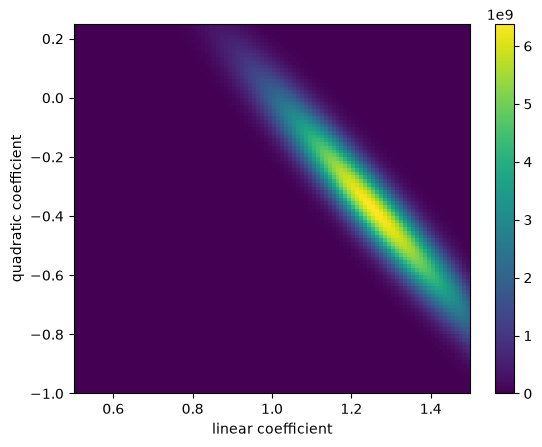

In [26]:
#part 4
#setting up grid
a_grid = np.linspace(0.5, 1.5, 100)   
b_grid = np.linspace(-1, 0.25, 100)    
lnL_2d = np.array([[logL([intercept, a, b], data2) for b in b_grid]
                   for a in a_grid])
#uniform priors
prior_a = 1 / (1.5 - 0.5)
prior_b = 1 / (0.25 - (-1))
prior_2d = prior_a * prior_b * np.ones_like(lnL_2d)
lnL2_max = lnL_2d.max()         

#posterior
posterior_2d = np.exp(lnL_2d) * prior_2d

#2d plot
plt.imshow(posterior_2d.T, origin="lower", aspect="auto",
           extent=[a_grid.min(), a_grid.max(), b_grid.min(), b_grid.max()])
plt.colorbar()
plt.xlabel("linear coefficient")
plt.ylabel("quadratic coefficient")
plt.show()

In [27]:
#part 5
#calculating evidence of quadratic model
integrand = np.exp(lnL_2d - lnL2_max) * prior_2d   
inner = np.trapezoid(integrand, b_grid, axis=1)
integral = np.trapezoid(inner, a_grid)
lnZ_quad = lnL2_max + np.log(integral)
Z_quad = np.exp(lnZ_quad)

print("evidence Z (quadratic):", Z_quad)

evidence Z (quadratic): 490433690.6169988


In [28]:
#part 6
#calculating bayes factor
ln_B_lin_quad = lnZ_linear - lnZ_quad
B_lin_quad = np.exp(ln_B_lin_quad)

print("Bayes factor (linear/quadratic):", B_lin_quad)

Bayes factor (linear/quadratic): 0.7456354246393679


In [29]:
#both say there's not much difference between the models
#the BIC values aren't that different, but linear is slightly favored
#~17 versus ~18
#the bayes factor is near 1
#0.74 means quadratic is slightly favored